# Gradient descent vs. NEAT

The same four problems, solved two ways:

- **Gradient descent:** you choose the network's shape, then backpropagation tunes the weights.
- **NEAT:** evolution finds both the shape and the weights, using only a fitness score.

Run the cells top to bottom (**Shift + Enter**). Add your own notes in the *Your notes* cells as you go.

In [1]:
# Setup: imports and shared helper code. Run this cell first.
import os, time, math, tempfile, contextlib, io, warnings
import numpy as np
import matplotlib.pyplot as plt
import neat

warnings.filterwarnings("ignore")
SEED = 0  # change this to see how much results depend on luck


# ---------- Gradient descent: a small network written from scratch ----------
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


class GDNet:
    """A network with ONE hidden layer whose size YOU choose.
    It learns with plain gradient descent + backpropagation."""

    def __init__(self, n_inputs=2, n_hidden=4, seed=0):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1, (n_inputs, n_hidden))  # input -> hidden weights
        self.b1 = np.zeros(n_hidden)                       # hidden biases
        self.W2 = rng.normal(0, 1, (n_hidden, 1))          # hidden -> output weights
        self.b2 = np.zeros(1)                              # output bias

    def forward(self, X):
        """Forward pass: weighted sum + sigmoid, layer by layer."""
        self.h = sigmoid(X @ self.W1 + self.b1)
        self.out = sigmoid(self.h @ self.W2 + self.b2)
        return self.out[:, 0]

    def train(self, X, y, lr=2.0, epochs=5000):
        """Gradient descent on mean squared error. Returns the loss at every step."""
        losses = []
        for _ in range(epochs):
            p = self.forward(X)
            err = p - y
            losses.append(np.mean(err ** 2))
            # Backpropagation: pass the error backward with the chain rule
            d_out = (2 * err / len(y) * p * (1 - p))[:, None]
            gW2, gb2 = self.h.T @ d_out, d_out.sum(0)
            d_h = d_out @ self.W2.T * self.h * (1 - self.h)
            gW1, gb1 = X.T @ d_h, d_h.sum(0)
            # Step downhill: w_new = w_old - learning_rate * slope
            self.W2 -= lr * gW2; self.b2 -= lr * gb2
            self.W1 -= lr * gW1; self.b1 -= lr * gb1
        return losses

    def n_params(self):
        return self.W1.size + self.b1.size + self.W2.size + self.b2.size

    def predict(self, X):
        return self.forward(np.asarray(X, float))


# ---------- NEAT: settings and a runner ----------
NEAT_SETTINGS = {
    "num_inputs": 2, "pop_size": 150, "fitness_threshold": 3.9,
    "node_add_prob": 0.2, "conn_add_prob": 0.5, "weight_mutate_power": 0.5,
    "activation_options": "sigmoid", "activation_mutate_rate": 0.0,
    "compatibility_threshold": 3.0,
}

NEAT_TEMPLATE = """
[NEAT]
fitness_criterion = max
fitness_threshold = {fitness_threshold}
pop_size = {pop_size}
reset_on_extinction = True
no_fitness_termination = False
[DefaultGenome]
num_inputs = {num_inputs}
num_hidden = 0
num_outputs = 1
initial_connection = full
feed_forward = True
activation_default = sigmoid
activation_mutate_rate = {activation_mutate_rate}
activation_options = {activation_options}
aggregation_default = sum
aggregation_mutate_rate = 0.0
aggregation_options = sum
bias_init_mean = 0.0
bias_init_stdev = 1.0
bias_max_value = 30.0
bias_min_value = -30.0
bias_mutate_power = {weight_mutate_power}
bias_mutate_rate = 0.7
bias_replace_rate = 0.1
response_init_mean = 1.0
response_init_stdev = 0.0
response_max_value = 30.0
response_min_value = -30.0
response_mutate_power = 0.0
response_mutate_rate = 0.0
response_replace_rate = 0.0
weight_init_mean = 0.0
weight_init_stdev = 1.0
weight_max_value = 30
weight_min_value = -30
weight_mutate_power = {weight_mutate_power}
weight_mutate_rate = 0.8
weight_replace_rate = 0.1
enabled_default = True
enabled_mutate_rate = 0.01
conn_add_prob = {conn_add_prob}
conn_delete_prob = 0.5
node_add_prob = {node_add_prob}
node_delete_prob = 0.2
compatibility_disjoint_coefficient = 1.0
compatibility_weight_coefficient = 0.5
[DefaultSpeciesSet]
compatibility_threshold = {compatibility_threshold}
[DefaultStagnation]
species_fitness_func = max
max_stagnation = 20
species_elitism = 2
[DefaultReproduction]
elitism = 2
survival_threshold = 0.2
"""


def run_neat(fitness_fn, changes=None, generations=300, seed=0):
    """Evolve networks with NEAT. fitness_fn(net) -> a score (higher is better).
    Returns (best genome, its network, config, stats, seconds)."""
    settings = dict(NEAT_SETTINGS, **(changes or {}))
    path = os.path.join(tempfile.gettempdir(), "neat_compare.ini")
    with open(path, "w") as f:
        f.write(NEAT_TEMPLATE.format(**settings))
    config = neat.Config(neat.DefaultGenome, neat.DefaultReproduction,
                         neat.DefaultSpeciesSet, neat.DefaultStagnation, path)

    def eval_genomes(genomes, config):
        for _, g in genomes:
            g.fitness = fitness_fn(neat.nn.FeedForwardNetwork.create(g, config))

    pop = neat.Population(config, seed=seed)
    stats = neat.StatisticsReporter()
    pop.add_reporter(stats)
    start = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        winner = pop.run(eval_genomes, generations)
    net = neat.nn.FeedForwardNetwork.create(winner, config)
    return winner, net, config, stats, time.time() - start


def neat_size(winner, config):
    """(hidden neurons, enabled connections, total parameters = weights + biases)"""
    hidden = sum(1 for k in winner.nodes if k not in config.genome_config.output_keys)
    conns = sum(c.enabled for c in winner.connections.values())
    return hidden, conns, conns + len(winner.nodes)


def neat_predict(net, X):
    return np.array([net.activate(x)[0] for x in X])


def accuracy(pred, y):
    return np.mean((pred > 0.5) == y)

print("Ready.")


Ready.


## Part 1: XOR

The smallest problem that needs a hidden neuron.

In [2]:
XOR_X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
XOR_Y = np.array([0, 1, 1, 0], float)

# Gradient descent: WE choose the shape (2 hidden neurons), it tunes the weights
start = time.time()
gd_xor = GDNet(n_hidden=2, seed=SEED)
gd_losses = gd_xor.train(XOR_X, XOR_Y, lr=2.0, epochs=5000)
gd_time = time.time() - start

print("Gradient descent outputs:", np.round(gd_xor.predict(XOR_X), 3))
print(f"Accuracy {accuracy(gd_xor.predict(XOR_X), XOR_Y):.0%}, "
      f"{gd_xor.n_params()} parameters, {gd_time:.2f} s")

Gradient descent outputs: [0.018 0.983 0.979 0.016]
Accuracy 100%, 9 parameters, 0.16 s


In [3]:
# NEAT: starts with NO hidden neurons and has to find the shape itself.
# Fitness = 4 minus squared error on the 4 cases (4 = perfect), same as xor_neat.py
def xor_fitness(net):
    return 4 - np.sum((neat_predict(net, XOR_X) - XOR_Y) ** 2)

w, neat_xor, cfg, stats, neat_time = run_neat(xor_fitness, generations=300, seed=SEED)
hidden, conns, params = neat_size(w, cfg)

print("NEAT outputs:", np.round(neat_predict(neat_xor, XOR_X), 3))
print(f"Accuracy {accuracy(neat_predict(neat_xor, XOR_X), XOR_Y):.0%}, "
      f"{hidden} hidden neuron(s), {params} parameters, "
      f"{len(stats.most_fit_genomes)} generations, {neat_time:.2f} s")

NEAT outputs: [0.239 0.873 1.    0.059]
Accuracy 100%, 1 hidden neuron(s), 7 parameters, 98 generations, 0.52 s


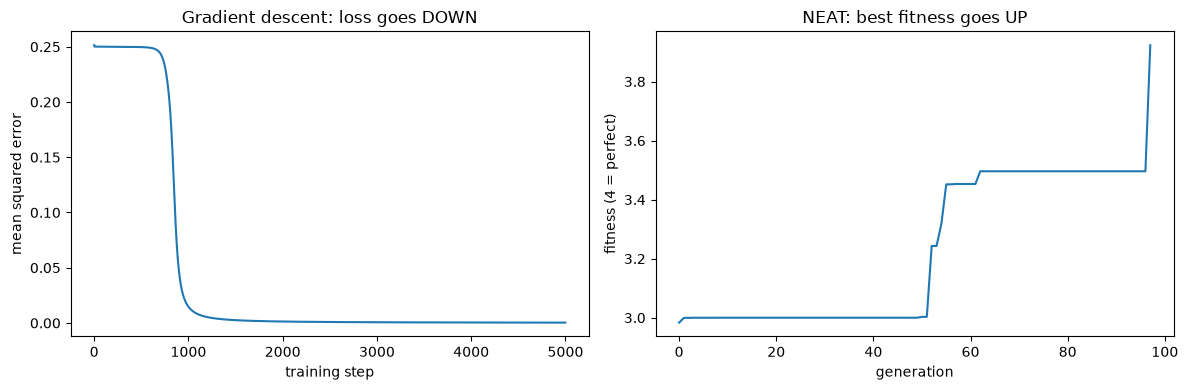

In [4]:
# How each method improved over time
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(gd_losses)
axes[0].set(title="Gradient descent: loss goes DOWN", xlabel="training step", ylabel="mean squared error")
axes[1].plot([g.fitness for g in stats.most_fit_genomes])
axes[1].set(title="NEAT: best fitness goes UP", xlabel="generation", ylabel="fitness (4 = perfect)")
plt.tight_layout(); plt.show()

**Your notes:**

- 


## Part 2: Inside or outside a circle

A harder pattern with 200 labeled points. With gradient descent we try two shapes: 2 hidden neurons and 4 hidden neurons.

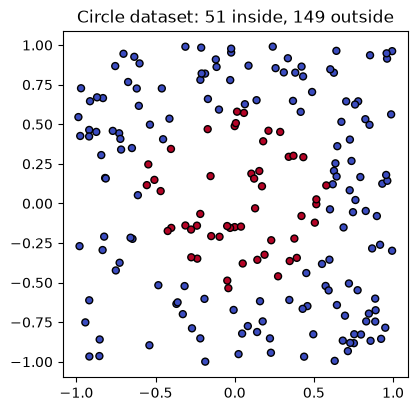

Note: always guessing 'outside' already scores 74%. Beat that!


In [5]:
def make_circles(n=200, seed=0):
    """Random points in a square. Label 1 if the point is inside a circle of radius 0.6."""
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (np.sqrt((X ** 2).sum(axis=1)) < 0.6).astype(float)
    return X, y

CX, CY = make_circles()
plt.figure(figsize=(4.5, 4.5))
plt.scatter(CX[:, 0], CX[:, 1], c=CY, cmap="coolwarm", edgecolors="k", s=25)
plt.title(f"Circle dataset: {int(CY.sum())} inside, {int(len(CY) - CY.sum())} outside")
plt.gca().set_aspect("equal"); plt.show()
print(f"Note: always guessing 'outside' already scores {1 - CY.mean():.0%}. Beat that!")

In [6]:
results = {}

# Gradient descent with two different shapes WE pick
for n_hidden in (2, 4):
    start = time.time()
    m = GDNet(n_hidden=n_hidden, seed=SEED)
    m.train(CX, CY, lr=2.0, epochs=5000)
    results[f"Gradient descent, {n_hidden} hidden"] = dict(
        acc=accuracy(m.predict(CX), CY), params=m.n_params(), secs=time.time() - start,
        predict=m.predict, hidden=n_hidden)

# NEAT finds its own shape. Fitness = 1 - mean squared error (1 = perfect).
# This takes about 20-40 seconds.
def circle_fitness(net):
    return 1 - np.mean((neat_predict(net, CX) - CY) ** 2)

w, net_c, cfg_c, stats_c, secs = run_neat(
    circle_fitness, {"fitness_threshold": 0.97}, generations=300, seed=SEED)
hidden, conns, params = neat_size(w, cfg_c)
results["NEAT"] = dict(acc=accuracy(neat_predict(net_c, CX), CY), params=params, secs=secs,
                       predict=lambda X, n=net_c: neat_predict(n, X), hidden=hidden)

print(f"{'method':28s} {'accuracy':>9s} {'hidden':>7s} {'params':>7s} {'seconds':>8s}")
for name, r in results.items():
    print(f"{name:28s} {r['acc']:9.1%} {r['hidden']:7d} {r['params']:7d} {r['secs']:8.1f}")

method                        accuracy  hidden  params  seconds
Gradient descent, 2 hidden       80.0%       2       9      0.1
Gradient descent, 4 hidden       98.5%       4      17      0.1
NEAT                             78.0%       1       5      9.9


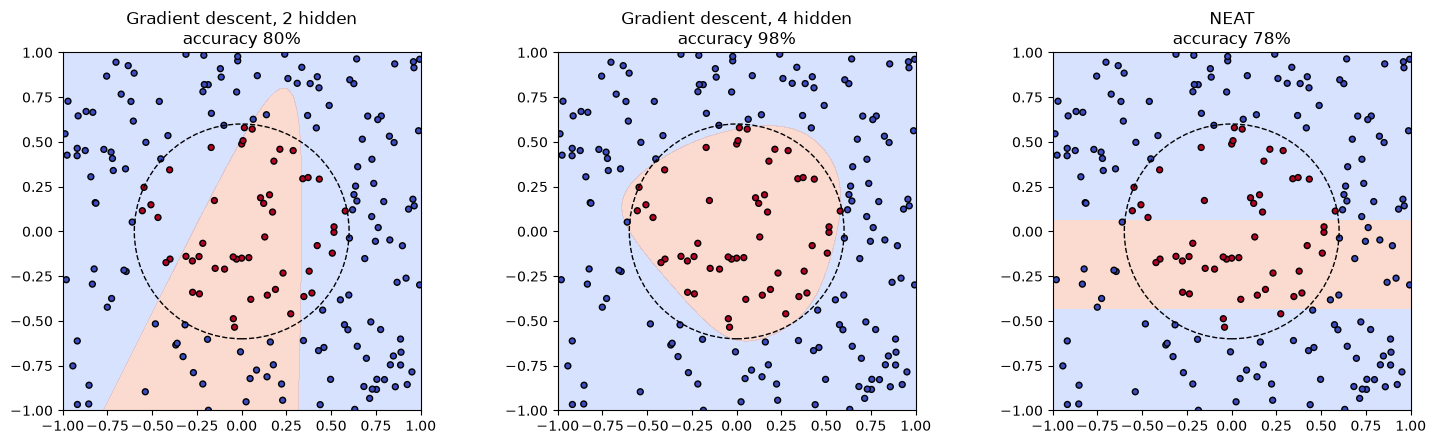

In [7]:
# What shape did each method learn? Background colour = the network's answer.
xs = np.linspace(-1, 1, 60)
gx, gy = np.meshgrid(xs, xs)
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4.5))
for ax, (name, r) in zip(axes, results.items()):
    z = r["predict"](grid).reshape(gx.shape)
    ax.contourf(gx, gy, z, levels=[0, 0.5, 1], cmap="coolwarm", alpha=0.35)
    ax.scatter(CX[:, 0], CX[:, 1], c=CY, cmap="coolwarm", edgecolors="k", s=18)
    ax.add_patch(plt.Circle((0, 0), 0.6, fill=False, ls="--"))
    ax.set_title(f"{name}\naccuracy {r['acc']:.0%}"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

**Your notes:**

- 


## Part 3: Balancing a pole (no right answers, only a score)

There's no labeled data here. Nobody knows the "correct" push at each moment; we only find out how long the pole stayed up. Gradient descent needs a correct answer to measure each error against, so it can't be used directly here. NEAT only needs the final score.

In [8]:
def cartpole_steps(policy, max_steps=500, seed=0):
    """Balance a pole on a moving cart (same physics as OpenAI Gym's CartPole).
    Each step the network sees (cart position, cart speed, pole angle, pole spin)
    and outputs a number: > 0.5 pushes right, otherwise left.
    Returns how many steps the pole stayed up (max 500 = 10 seconds)."""
    rng = np.random.default_rng(seed)
    x, x_dot, th, th_dot = rng.uniform(-0.05, 0.05, 4)
    g, m_cart, m_pole, length, force_mag, dt = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    for t in range(max_steps):
        force = force_mag if policy((x, x_dot, th, th_dot)) > 0.5 else -force_mag
        cos, sin = math.cos(th), math.sin(th)
        temp = (force + m_pole * length * th_dot ** 2 * sin) / (m_cart + m_pole)
        th_acc = (g * sin - cos * temp) / (length * (4 / 3 - m_pole * cos ** 2 / (m_cart + m_pole)))
        x_acc = temp - m_pole * length * th_acc * cos / (m_cart + m_pole)
        x, x_dot = x + dt * x_dot, x_dot + dt * x_acc
        th, th_dot = th + dt * th_dot, th_dot + dt * th_acc
        if abs(x) > 2.4 or abs(th) > math.radians(12):  # cart off the track or pole fell
            return t + 1
    return max_steps

# Fitness = average steps balanced over 3 different starting positions
def cart_fitness(net):
    return np.mean([cartpole_steps(lambda s: net.activate(s)[0], seed=k) for k in range(3)])

w, net_p, cfg_p, stats_p, secs = run_neat(
    cart_fitness, {"num_inputs": 4, "fitness_threshold": 499}, generations=100, seed=SEED)
hidden, conns, params = neat_size(w, cfg_p)

# Test on 10 starting positions it never trained on
test = [cartpole_steps(lambda s: net_p.activate(s)[0], seed=k) for k in range(100, 110)]
random_policy = [cartpole_steps(lambda s: np.random.rand(), seed=k) for k in range(100, 110)]
print(f"NEAT: {len(stats_p.most_fit_genomes)} generation(s), {secs:.1f} s, "
      f"{hidden} hidden neuron(s), {params} parameters")
print(f"Steps balanced on new starts (max 500): NEAT {np.mean(test):.0f}, random pushing {np.mean(random_policy):.0f}")

NEAT: 1 generation(s), 0.0 s, 0 hidden neuron(s), 5 parameters
Steps balanced on new starts (max 500): NEAT 500, random pushing 24


**Your notes:**

- 


## Part 4: Is it a 7? Real handwriting

Handwritten digits, each 8×8 pixels, so the network gets 64 inputs. The question: is this a 7 or not? Both methods train on some digits and are tested on digits they never saw.

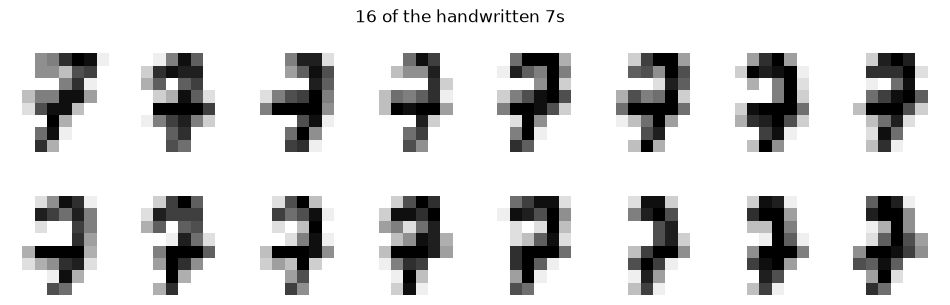

179 sevens out of 1797 digits. Training on 1200, testing on 597.


In [9]:
# Load ~1,800 handwritten digits that come with scikit-learn (8 x 8 pixels each)
from sklearn.datasets import load_digits

digits = load_digits()
DX = digits.data / 16.0                    # 64 pixel brightnesses per image, scaled 0 to 1
DY = (digits.target == 7).astype(float)    # 1 if the digit is a 7, else 0

rng = np.random.default_rng(SEED)
order = rng.permutation(len(DY))
train, test = order[:1200], order[1200:]   # test digits are never seen during training

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.ravel(), np.where(DY == 1)[0][:16]):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.axis("off")
fig.suptitle("16 of the handwritten 7s")
plt.show()
print(f"{int(DY.sum())} sevens out of {len(DY)} digits. Training on {len(train)}, testing on {len(test)}.")

In [10]:
def balanced_accuracy(pred, y):
    """Average of (% of 7s caught) and (% of non-7s correctly rejected).
    Plain accuracy would mislead: answering 'not a 7' every time already scores 90%."""
    p = pred > 0.5
    return 0.5 * (np.mean(p[y == 1]) + np.mean(~p[y == 0]))

# Gradient descent: 64 inputs, 8 hidden neurons (our choice), 1 output
start = time.time()
gd7 = GDNet(n_inputs=64, n_hidden=8, seed=SEED)
gd7.train(DX[train], DY[train], lr=2.0, epochs=2000)
gd7_secs = time.time() - start

# NEAT: fitness = balanced accuracy on the training 7s plus twice as many non-7s
# (a smaller, balanced sample keeps each generation fast)
pos = train[DY[train] == 1]
neg = train[DY[train] == 0][: 2 * len(pos)]
fit_idx = np.r_[pos, neg]

def seven_fitness(net):
    return balanced_accuracy(neat_predict(net, DX[fit_idx]), DY[fit_idx])

w7, neat7, cfg7, stats7, neat7_secs = run_neat(
    seven_fitness, {"num_inputs": 64, "fitness_threshold": 0.97}, generations=100, seed=SEED)
h7, c7, p7 = neat_size(w7, cfg7)

gd_test = gd7.predict(DX[test])
neat_test = neat_predict(neat7, DX[test])

print(f"{'method':18s} {'test score':>10s} {'hidden':>7s} {'params':>7s} {'seconds':>8s}")
print(f"{'Gradient descent':18s} {balanced_accuracy(gd_test, DY[test]):10.1%} {8:7d} {gd7.n_params():7d} {gd7_secs:8.1f}")
print(f"{'NEAT':18s} {balanced_accuracy(neat_test, DY[test]):10.1%} {h7:7d} {p7:7d} {neat7_secs:8.1f}")
print(f"\nNEAT finished in {len(stats7.most_fit_genomes)} generations.")

method             test score  hidden  params  seconds
Gradient descent        97.6%       8     529      0.2
NEAT                    95.0%       0      44      5.0

NEAT finished in 12 generations.


NEAT got 45 of 597 test digits wrong.


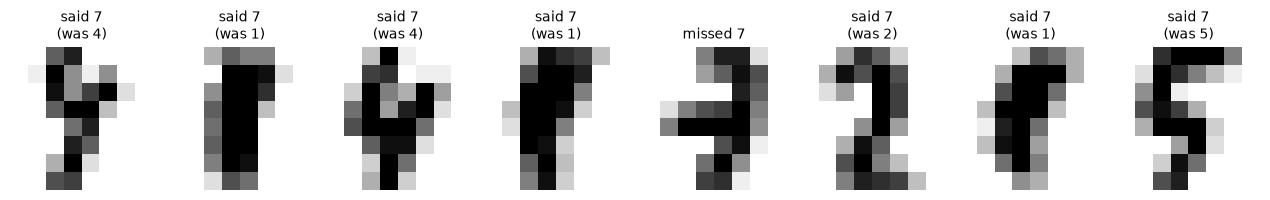

In [11]:
# Which test digits did NEAT get wrong?
wrong = np.where((neat_test > 0.5) != (DY[test] == 1))[0]
print(f"NEAT got {len(wrong)} of {len(test)} test digits wrong.")
if len(wrong):
    n = min(8, len(wrong))
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2), squeeze=False)
    for ax, k in zip(axes[0], wrong[:n]):
        i = test[k]
        ax.imshow(digits.images[i], cmap="gray_r")
        ax.set_title("missed 7" if DY[i] == 1 else f"said 7\n(was {digits.target[i]})", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

**Your notes:**

- 


## Ideas for your own questions

- Change `SEED` at the top and rerun. Are the results the same every time?
- Give gradient descent 8 hidden neurons, or change its learning rate `lr`.
- Let NEAT use other activation functions: `run_neat(circle_fitness, {"fitness_threshold": 0.97, "activation_options": "sigmoid gauss", "activation_mutate_rate": 0.2})`
- Give NEAT more generations or a bigger `pop_size` on the circle problem.
- In Part 3, what happens if the network only sees the pole angle?